In [3]:
%pylab inline

nzs=4
import gc
import glob
import fitsio
import anautil
import numpy as np
import matplotlib.cm as cm
import numpy.lib.recfunctions as rfn
fieldname='XMM'
outDir='/work/xiangchong.li/work/cosmicShear/s16a/photoz/'

Populating the interactive namespace from numpy and matplotlib


In [4]:
cd /work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut


In [5]:
def main(pzname,iz=0,plot=False):
    pzDir=os.path.join('catalog_tracts','XMM_tracts')
    pbins= pyfits.getdata(os.path.join(pzDir,'8522_pz_pdf_%s.fits' %pzname),ext=2)['BINS']
    inDir  =   os.path.join('catalog_tracts','%s_tracts' %fieldname) 
    fnames=glob.glob(os.path.join(inDir,'*_pz_pdf_%s.fits' %(pzname)))
    pTest=[]
    for pfname in fnames[:10]:
        pata=pyfits.getdata(pfname)
        fname=pfname.split('pz_pdf')[0]+'pz.fits'
        data=pyfits.getdata(fname)
        poz_best=data['dnnz_photoz_best']# fix the best-fit estimation code for binning
        del data,fname
        fname=pfname.split('pz_pdf')[0]+'no_m.fits'
        zmin=   (iz+1)*0.3
        zmax=   (iz+2)*0.3
        tmp_msk=(poz_best>zmin)&(poz_best<=zmax)
        pTest.append(pata[tmp_msk]['PDF'])
        del tmp_msk,pata
        gc.collect()
    pTest=np.vstack(pTest)
    out=np.log10(np.sum(pTest[:,pbins>2.],axis=1)/np.sum(pTest,axis=1))
    if plot:
        plt.close()
        _=plt.hist(out,bins=40,range=(-8,0),density=True,label=pzname)
        plt.xlabel(r'$log_{10}(P(>2))$')
        plt.legend()
    return pbins,pTest,out

In [6]:
#pzname='mizuki'
#pzname='dempz'

pb1,pTest1,out1=main('dnnz',iz=0)
pb2,pTest2,out2=main('dnnz',iz=1)
pb3,pTest3,out3=main('dnnz',iz=2)
pb4,pTest4,out4=main('dnnz',iz=3)
np.sum(out1<-0.5)/len(out1)

/tmp/ipykernel_10965/266581978.py:21: RuntimeWarning: divide by zero encountered in log10
  out=np.log10(np.sum(pTest[:,pbins>2.],axis=1)/np.sum(pTest,axis=1))


0.9469731321169235

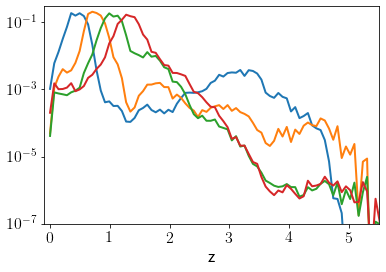

In [8]:
plt.close()
pStack1=np.average(pTest1,axis=0)
pStack2=np.average(pTest2,axis=0)
pStack3=np.average(pTest3,axis=0)
pStack4=np.average(pTest4,axis=0)
plt.plot(pb1,pStack1)
plt.plot(pb2,pStack2)
plt.plot(pb3,pStack3)
plt.plot(pb4,pStack4)
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')


nzList=[pStack1,pStack2,pStack3,pStack4]
t=anautil.make_nz_hdu(nzList,pb1)
#t.writeto(os.path.join(outDir,'HSC_Y3.fits'),overwrite=True)

In [9]:
pb1

array([0.        , 0.07070707, 0.14141414, 0.21212122, 0.28282827,
       0.35353535, 0.42424244, 0.4949495 , 0.56565654, 0.6363636 ,
       0.7070707 , 0.7777778 , 0.8484849 , 0.9191919 , 0.989899  ,
       1.060606  , 1.1313131 , 1.2020202 , 1.2727273 , 1.3434343 ,
       1.4141414 , 1.4848485 , 1.5555556 , 1.6262627 , 1.6969697 ,
       1.7676767 , 1.8383838 , 1.9090909 , 1.979798  , 2.0505052 ,
       2.121212  , 2.191919  , 2.2626262 , 2.3333333 , 2.4040403 ,
       2.4747474 , 2.5454545 , 2.6161616 , 2.6868687 , 2.7575758 ,
       2.8282828 , 2.89899   , 2.969697  , 3.040404  , 3.1111112 ,
       3.1818182 , 3.2525253 , 3.3232324 , 3.3939395 , 3.4646466 ,
       3.5353534 , 3.6060605 , 3.6767676 , 3.7474747 , 3.8181818 ,
       3.8888888 , 3.959596  , 4.030303  , 4.1010103 , 4.171717  ,
       4.242424  , 4.3131313 , 4.383838  , 4.4545455 , 4.5252523 ,
       4.5959597 , 4.6666665 , 4.737374  , 4.8080807 , 4.878788  ,
       4.949495  , 5.020202  , 5.090909  , 5.1616163 , 5.23232

0.07070707


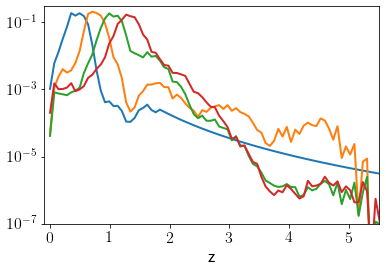

In [9]:
zlow=pb1-(pb1[1]-pb1[0])
zmid=pb1
zhigh=pb1+(pb1[1]-pb1[0])
pStack1Ext=pStack1.copy()
pStack1Ext[zmid>1.8]=pStack1Ext[zmid>1.8][0]*(pb1[zmid>1.8]/pb1[zmid>1.8][0])**-4

plt.plot(pb1,pStack1Ext)
plt.plot(pb2,pStack2)
plt.plot(pb3,pStack3)
plt.plot(pb4,pStack4)
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')

nzList=[pStack1Ext,pStack2,pStack3,pStack4]
t=anautil.make_nz_hdu(nzList,pb1)
del nzList
gc.collect()
t.writeto(os.path.join(outDir,'HSC_Y3_ext.fits'),overwrite=True)

In [15]:
t.data['Z_LOW']

array([-0.03535353,  0.03535353,  0.1060606 ,  0.17676768,  0.24747473,
        0.31818181,  0.3888889 ,  0.45959595,  0.530303  ,  0.60101008,
        0.67171717,  0.74242425,  0.81313133,  0.88383836,  0.95454544,
        1.02525246,  1.09595954,  1.16666663,  1.23737371,  1.30808079,
        1.37878788,  1.44949496,  1.52020204,  1.59090912,  1.66161621,
        1.73232317,  1.80303025,  1.87373734,  1.94444442,  2.01515174,
        2.08585858,  2.15656567,  2.22727275,  2.29797983,  2.36868691,
        2.439394  ,  2.51010108,  2.58080816,  2.65151525,  2.72222233,
        2.79292941,  2.86363649,  2.93434358,  3.00505066,  3.07575774,
        3.14646482,  3.21717191,  3.28787899,  3.35858607,  3.42929316,
        3.5       ,  3.57070708,  3.64141417,  3.71212125,  3.78282833,
        3.85353541,  3.9242425 ,  3.99494958,  4.06565666,  4.13636351,
        4.20707035,  4.27777767,  4.34848452,  4.41919184,  4.48989868,
        4.560606  ,  4.63131285,  4.70202017,  4.77272701,  4.84

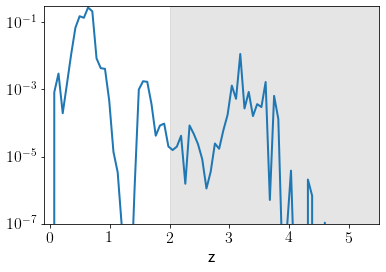

In [28]:
# single poz
plt.plot(pb1,pTest1[1])
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

0.02910323
with DNNZ \int{P(>2)}< 0.3162
0.012798807
with DNNZ \int{P(>2)}< 0.1585
0.004468135
with DNNZ \int{P(>2)}< 0.0631


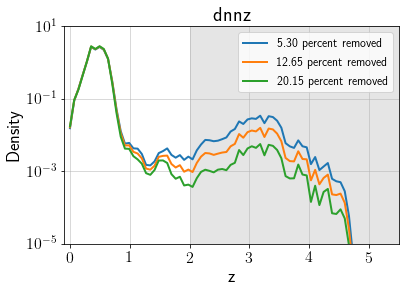

In [69]:
#stack
for thres in [-0.5,-.8,-1.2]:
    stackTmp=np.average(pTest1[out1<thres],axis=0)/(pb1[1]-pb1[0])
    print(np.sum(stackTmp[pb1>2.0])*(pb1[1]-pb1[0]))
    plt.plot(pb1,stackTmp,label='%.2f percent removed' %(100-np.sum(out1<thres)/len(out1)*100.))
    del stackTmp
    gc.collect()
    print(r'with DNNZ \int{P(>2)}< %.4f' %(10**(thres)))
plt.axvspan(2,10,alpha=0.2, color='grey')
plt.legend(loc='upper right',fontsize=12)
plt.title('dnnz',fontsize=20)
plt.yscale('log')
plt.ylabel('Density')
plt.xlabel('z')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.grid()

In [51]:
pb1,pTest1,out1=main('dempz')
pb2,pTest2,out2=main('dempz',iz=1)
pb3,pTest3,out3=main('dempz',iz=2)
pb4,pTest4,out4=main('dempz',iz=3)
np.sum(out2<-0.5)/len(out2)

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:21: RuntimeWarning: divide by zero encountered in log10


0.9877359484809993

Text(0.5, 0, 'z')

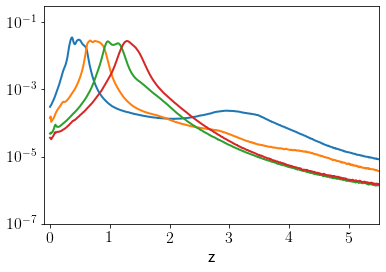

In [52]:
plt.close()
pstack1=np.average(pTest1,axis=0)
pstack2=np.average(pTest2,axis=0)
pstack3=np.average(pTest3,axis=0)
pstack4=np.average(pTest4,axis=0)
plt.plot(pb1,pstack1)
plt.plot(pb2,pstack2)
plt.plot(pb3,pstack3)
plt.plot(pb4,pstack4)
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')

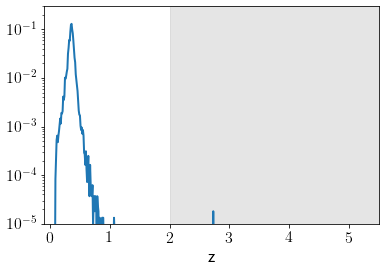

In [53]:
plt.plot(pb1,pTest1[1])
plt.yscale('log')
plt.ylim(1e-5,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

remove 0.00 percent galaxies
with DEMPZ P(>2) < 1.0000


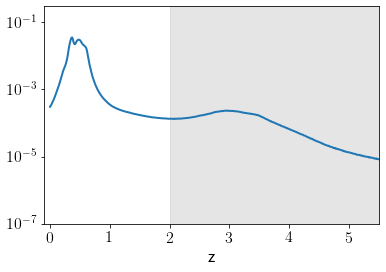

In [55]:
thres=-0.
plt.plot(pb1,np.average(pTest1[out1<thres],axis=0))
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')
print('remove %.2f percent galaxies' %(100-np.sum(out2<thres)/len(out2)*100.))
print('with DEMPZ P(>2) < %.4f' %(10**(thres)))

In [47]:
pb3,pTest3,out3=main('mizuki')

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:21: RuntimeWarning: divide by zero encountered in log10


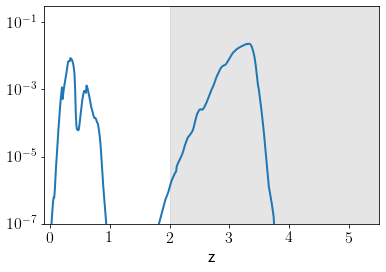

In [35]:
plt.plot(pb3,pTest3[1])
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

0.024282815
with MIZUKIZ P(>2) < 0.3162
0.010709959
with MIZUKIZ P(>2) < 0.1585
0.0036623569
with MIZUKIZ P(>2) < 0.0631


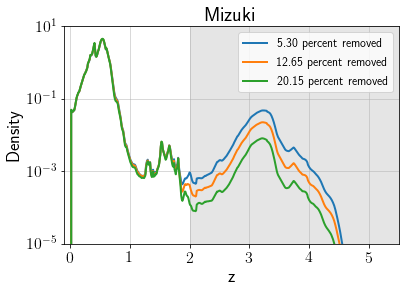

In [70]:
for thres in [-0.5,-.8,-1.2]:
    stackTmp=np.average(pTest3[out3<thres],axis=0)/(pb3[1]-pb3[0])
    print(np.sum(stackTmp[pb3>2.0])*(pb3[1]-pb3[0]))
    plt.plot(pb3,stackTmp,label='%.2f percent removed' %(100-np.sum(out1<thres)/len(out1)*100.))
    del stackTmp
    gc.collect()
    plt.yscale('log')
    plt.xlabel('z')
    print('with MIZUKIZ P(>2) < %.4f' %(10**(thres)))
    
plt.title('Mizuki',fontsize=20)
plt.ylabel('Density')
plt.ylim(1e-5,1e1)
plt.xlim(-0.1,5.5)
plt.axvspan(2,10,alpha=0.2, color='grey')
plt.legend(loc='upper right',fontsize=12)
plt.grid()